# Feature Engineering

**Goal:** create new features that bring business knowledge the model could not find on its own.

## 0. Setup

Imports and load the cleaned dataset.

`buildings_cleaned.parquet` is the output of the last section of `01_eda.ipynb`

To generate it:

1. Make sure the raw file `data/raw/2016_Building_Energy_Benchmarking.csv` is present.
2. Run `notebooks/01_eda.ipynb` from top to bottom.
3. The file is written to `data/processed/buildings_cleaned.parquet`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

df = pd.read_parquet("../data/processed/buildings_cleaned.parquet")
print(f"Dataset: {df.shape[0]} rows x {df.shape[1]} columns")

Dataset: 1536 rows x 13 columns


## 1. Parking share

A parking area has its own energy use (lighting, ventilation), which is counted in the total energy use of the property. The larger the parking relative to the building, the more it should weigh.

**Definition:** `ParkingShare = PropertyGFAParking / (PropertyGFABuilding(s) + PropertyGFAParking)`. It is 0 for properties without parking (a real value, not a missing one) and strictly below 1 as long as the building area is positive.

In [2]:
b = df["PropertyGFABuilding(s)"]
p = df["PropertyGFAParking"]

assert (b > 0).all(), "A property without building area would make the share equal to 1"
df["ParkingShare"] = p / (b + p)

has_parking = p > 0
print(
    f"Properties with a parking: {has_parking.sum()} / {len(df)} ({has_parking.mean():.1%})"
)
df.loc[has_parking, "ParkingShare"].describe()

Properties with a parking: 325 / 1536 (21.2%)


count    325.000000
mean       0.306185
std        0.150359
min        0.015281
25%        0.190961
50%        0.290781
75%        0.389316
max        0.798167
Name: ParkingShare, dtype: float64

### Presence or share of the parking?

79% of the properties have no parking, so the share has a large mass at 0. Two questions: how is the share distributed among properties with a parking, and which signal (has a parking or not / how large it is) relates best to energy use?

Energy use is strongly driven by building size, so it is divided by the building area (parking excluded) and log-transformed to compare buildings of different sizes.

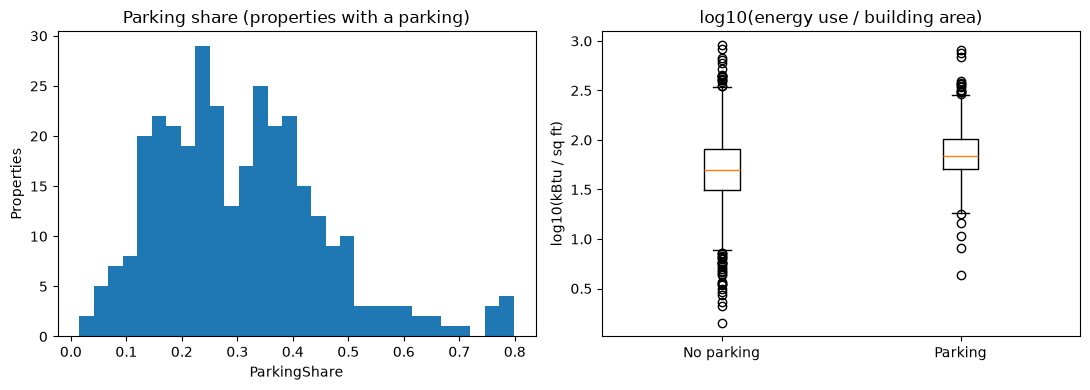

,Spearman with log intensity
HasParking (all properties),0.22
ParkingShare (all properties),0.23
ParkingShare (properties with a parking),0.26


In [3]:
target = df["SiteEnergyUse(kBtu)"]
log_intensity = np.log10(target / b)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df.loc[has_parking, "ParkingShare"], bins=30)
axes[0].set(
    title="Parking share (properties with a parking)",
    xlabel="ParkingShare",
    ylabel="Properties",
)
axes[1].boxplot(
    [log_intensity[~has_parking], log_intensity[has_parking]],
    tick_labels=["No parking", "Parking"],
)
axes[1].set(title="log10(energy use / building area)", ylabel="log10(kBtu / sq ft)")
plt.tight_layout()
plt.show()

correlations = {
    "HasParking (all properties)": spearmanr(has_parking, log_intensity).statistic,
    "ParkingShare (all properties)": spearmanr(
        df["ParkingShare"], log_intensity
    ).statistic,
    "ParkingShare (properties with a parking)": spearmanr(
        df.loc[has_parking, "ParkingShare"], log_intensity[has_parking]
    ).statistic,
}
pd.Series(correlations, name="Spearman with log intensity").round(2).to_frame()

### Decisions

The correlations are positive. For the same building area, properties with a parking use more energy.

On all properties, the flag and the share are equivalent (0.22 vs 0.23). Among properties with a parking, the share still correlates with intensity (0.26): the size of the parking matters, not only its presence. `ParkingShare` alone is kept, no `HasParking` flag.

Together with the building area, `ParkingShare` carries the same information in the form that matches the hypothesis (a proportion), without adding another variable correlated with size. `PropertyGFAParking` is dropped.

## 2. Mixed usage

A property hosting several activities (e.g. offices and a restaurant) has a different energy profile from a single-use property of the same type.

First, look at what `SecondLargestPropertyUseType` contains, and in particular how much of it is "Parking" (already captured by `ParkingShare`).

Properties with a second use type: 832 / 1536 (54.2%)
Share of 'Parking' among second use types: 39.5%


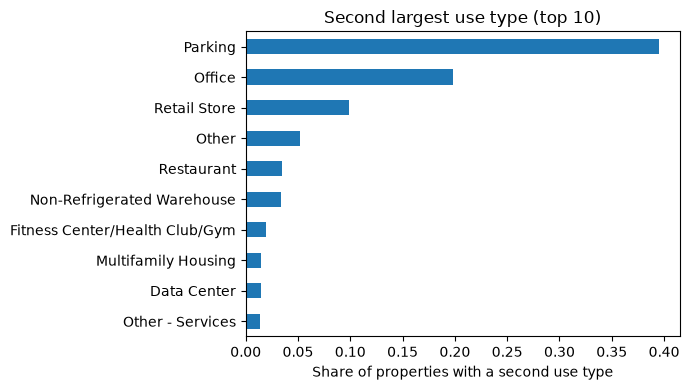

,count,share
SecondLargestPropertyUseType,,
Parking,329,0.395
Office,165,0.198
Retail Store,82,0.099
Other,43,0.052
Restaurant,29,0.035
Non-Refrigerated Warehouse,28,0.034
Fitness Center/Health Club/Gym,16,0.019
Data Center,12,0.014
Multifamily Housing,12,0.014


In [4]:
second = df["SecondLargestPropertyUseType"]
n_second = second.notna().sum()
print(
    f"Properties with a second use type: {n_second} / {len(df)} ({n_second / len(df):.1%})"
)

breakdown = second.value_counts().to_frame("count")
breakdown["share"] = breakdown["count"] / n_second
print(
    f"Share of 'Parking' among second use types: {breakdown.loc['Parking', 'share']:.1%}"
)

top = breakdown.head(10)
ax = top["share"].sort_values().plot.barh(figsize=(7, 4))
ax.set(
    title="Second largest use type (top 10)",
    xlabel="Share of properties with a second use type",
    ylabel="",
)
plt.tight_layout()
plt.show()

top.round(3)

Parking is the most frequent second use (40%). A flag based on "has a second use type" would mostly duplicate the parking information. Moreover, the two sources about parking do not agree: 329 properties declare Parking as second use, 325 have a parking area, and only 201 have both. `PropertyGFAParking` (through `ParkingShare`) is used as the reference for parking, and **Parking is excluded from the mixed-usage definition**.

### All declared use types

`ListOfAllPropertyUseTypes` lists all the use types of a property, including minor ones hidden by the two largest.

In [5]:
combinations = df["ListOfAllPropertyUseTypes"].value_counts()
print(
    f"Distinct combinations: {len(combinations)} (appearing once: {(combinations == 1).sum()})"
)
combinations.head(20).to_frame("count")

Distinct combinations: 360 (appearing once: 244)


,count
ListOfAllPropertyUseTypes,
Office,132
"Office, Parking",119
Non-Refrigerated Warehouse,100
"Non-Refrigerated Warehouse, Office",61
Other,58
Retail Store,52
K-12 School,46
Worship Facility,46
Hotel,43


### Split the list into use types

Some labels contain commas, e.g. `Repair Services (Vehicle, Shoe, Locksmith, etc)`, so the list is split on commas that are not inside parentheses.

In [6]:
all_uses = df["ListOfAllPropertyUseTypes"]
assert all_uses.notna().all(), "NaN would be counted as a use type after explode"

# Split on commas that are not inside parentheses
use_types = all_uses.str.split(r",\s*(?![^()]*\))", regex=True).explode()

# Check: labels that never appear as largest or second largest use
reference = set(df["LargestPropertyUseType"].dropna()) | set(second.dropna())
use_types[~use_types.isin(reference)].value_counts().to_frame("properties")

,properties
ListOfAllPropertyUseTypes,
Other - Technology/Science,6
Fast Food Restaurant,2
Outpatient Rehabilitation/Physical Therapy,2
Energy/Power Station,1
Single Family Home,1
Vocat,1


Only 6 labels never appear as largest or second largest use. Five are valid Portfolio Manager use types, minor in every property that declares them. `Vocat` is a truncated `Vocational School`: one list is cut at 255 characters. This does not affect the mixed-usage flag (that property declares 11 uses). The split is therefore correct.

In [7]:
# Number of distinct use types, parking excluded
n_uses = (
    use_types[use_types != "Parking"]
    .groupby(level=0)
    .nunique()
    .reindex(df.index, fill_value=0)  # properties declaring only Parking
)
print(
    f"Properties with more than one use (parking excluded): "
    f"{(n_uses > 1).sum()} / {len(df)} ({(n_uses > 1).mean():.1%})"
)
n_uses.value_counts().sort_index().to_frame("properties")

Properties with more than one use (parking excluded): 592 / 1536 (38.5%)


,properties
ListOfAllPropertyUseTypes,
1,944
2,351
3,149
4,56
5,22
6,8
7,1
8,2
9,2


Definition of `HasMixedUsage`

Two possible definitions:

- **Variant A:** `SecondLargestPropertyUseType` is specified and is not "Parking" (considers only the two largest uses).
- **Variant B:** at least two distinct uses other than "Parking" in `ListOfAllPropertyUseTypes` (considers all declared uses).

In [8]:
variant_a = second.notna() & (second != "Parking")
variant_b = n_uses >= 2

print(
    f"Variant A: {variant_a.sum()} ({variant_a.mean():.1%}) | Variant B: {variant_b.sum()} ({variant_b.mean():.1%})"
)
pd.crosstab(variant_a.rename("Variant A"), variant_b.rename("Variant B"), margins=True)

Variant A: 503 (32.7%) | Variant B: 592 (38.5%)


Variant B,False,True,All
Variant A,,,
False,932,101,1033
True,12,491,503
All,944,592,1536


The variants disagree on 113 properties.

**A False, B True (101):** Parking is the second largest use, so A misses the real second activity ranked third (e.g. `Hotel, Parking, Restaurant`).

**A True, B False (12):** listed below.

In [9]:
use_columns = [
    "LargestPropertyUseType",
    "SecondLargestPropertyUseType",
    "ListOfAllPropertyUseTypes",
]
df.loc[variant_a & ~variant_b, use_columns]

,LargestPropertyUseType,SecondLargestPropertyUseType,ListOfAllPropertyUseTypes
47,Hotel,Restaurant,Hotel
326,Parking,Retail Store,"Parking, Retail Store"
368,Parking,Medical Office,"Medical Office, Parking"
449,Parking,Office,"Office, Parking"
468,Other,Retail Store,Retail Store
857,Parking,K-12 School,"K-12 School, Parking"
1122,Parking,Retail Store,"Parking, Retail Store"
1181,Parking,Office,"Office, Parking"
1444,Parking,Other - Entertainment/Public Assembly,"Other - Entertainment/Public Assembly, Parking"
1449,Office,Office,Office


- 9 properties have Parking as largest use and a single other activity (e.g. a parking garage with retail on the ground floor). B considers them single-use once the parking is set aside, which is consistent with the parking being handled by `ParkingShare`.
- 3 properties have inconsistent declarations: a second use absent from the list (`Hotel` + `Restaurant`, `Other` + `Retail Store`) or identical to the first one (`Office` + `Office`).

### Decision

**Variant B is kept:** it does not depend on the rank of Parking and uses all the declared uses. With 592 mixed vs 944 single-use properties, both groups are large enough for the flag to be learned.

In [10]:
df["HasMixedUsage"] = variant_b.astype(int)
df["HasMixedUsage"].value_counts().to_frame("properties")

,properties
HasMixedUsage,
0,944
1,592


## 3. Construction period

fixed, business-justified bounds (e.g. successive energy codes), at least a few dozen properties per period.

## 4. Floor area per floor

`PropertyGFABuilding(s) / NumberofFloors`, check campuses (`NumberofBuildings > 1`) and extreme values.